In [1]:
from get_data.get_data import get_merged_events
from sequences.which_sector import *
from sequences.get_sequences import *
from sequences.get_sequences import get_sequence_location
import pandas as pd
from dataframe_modify.add_positions import add_positions
from dataframe_modify.swap_perspective import swap_y
from dataframe_modify.swap_perspective import generalize_perspective
from dataframe_modify.grid_areas import add_grid_areas
from dataframe_modify.add_context import add_context
from get_data.get_data import get_sb360
from sequences.get_sequences import get_sequences_by_possession
import time
from get_data.get_data import *
from get_data.get_season_data import *
from sequences.analyze_sequences import *


def_areas_x = 12
def_areas_y = 8

events_types_to_analize = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'duels', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots', 'goal_keepers']

events_types_to_analize = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'duels', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'half_ends', 'interceptions', 'miscontrols', 'shots', 'goal_keepers']


In [2]:
comps = sb.competitions()
comps = pd.DataFrame(comps)
comps

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
0,38,235,Poland,Ekstraklasa,male,False,False,2022/2023,2023-01-22T07:27:46.682057,2023-01-06T15:54:38.081295,2023-01-06T15:54:38.081295,2023-01-22T07:27:46.682057
1,38,108,Poland,Ekstraklasa,male,False,False,2021/2022,2023-01-16T10:46:03.470167,2022-11-27T21:38:48.731552,2022-11-27T21:38:48.731552,2023-01-16T10:46:03.470167
2,38,90,Poland,Ekstraklasa,male,False,False,2020/2021,2022-11-24T20:55:43.582874,2022-08-16T20:44:23.378841,None,2022-11-24T20:55:43.582874
3,38,42,Poland,Ekstraklasa,male,False,False,2019/2020,2023-01-04T18:15:24.553708,2021-06-13T16:17:31.694,None,2023-01-04T18:15:24.553708
4,38,4,Poland,Ekstraklasa,male,False,False,2018/2019,2022-11-21T04:43:34.590780,2021-06-13T16:17:31.694,None,2022-11-21T04:43:34.590780
5,55,43,Europe,UEFA Euro,male,False,True,2020,2022-12-01T16:36:28.219097,2022-08-04T12:00,2022-08-04T12:00,2022-12-01T16:36:28.219097


In [3]:
matches_2022_2023 = get_matches(38, 235)
matches_2021_2022 = get_matches(38, 108)


# matches_2022_2023.loc[matches_2022_2023.loc['home_team'] == 'Lech Poznań' or matches_2022_2023.loc['away_team'] == 'Lech Poznań']

In [4]:
lech = get_matches_team_season(matches_2022_2023, 'Lech Poznan')
len(lech)

34

In [5]:
# matches_2022_2023 = [3836175, 3836192, 3836200, 3836214, 3836226, 3836220, 3836236, 3836244, 3836260, 3836262, 3836275, 3836284, 3836289, 3836301, 3836312, 3836322]
matches_2021_2022_ids = get_season_matches_ids(matches_2021_2022)
matches_2022_2023_ids = get_season_matches_ids(matches_2022_2023)

matches_2022_2023_ids = matches_2022_2023_ids[:2]

list_goal_corners = []
list_shots_saved = []
list_saved_shots = []
list_inswinging_passes = []
list_outswinging_passes = []
list_straight_passes = []

all_corners = 0

for match_id in matches_2022_2023_ids:
    print(match_id)
    events = get_merged_events(events_types_to_analize, match_id)
    start_team = events['possession_team'][0]
    frames = get_sb360(match_id)
    # events = add_context(events, frames)
    # events = add_positions(events)
    ## events = swap_y(events)
    ## events = generalize_perspective(events, start_team)
    # events = add_grid_areas(events)

    sequences = get_sequences_by_possession(events)
    corners = get_corners_sequences(sequences)
    all_corners += len(corners)
    goals = get_goals_sequences(corners)
    shots_saved_gk = get_gk_accurate_shot_saved_sequences(corners)
    saved_shots = get_saved_shots_sequences(corners)
    inswinging_passes = get_inswinging_pasees_sequences(corners)
    outswinging_passes = get_outswinging_pasees_sequences(corners)
    straight_passes = get_straight_pasees_sequences(corners)
    

    if len(goals) > 0:
        for i in range(len(goals)):
            goals[i] = add_context(goals[i], frames)
            goals[i] = add_positions(goals[i])
            goals[i] = swap_y(goals[i])
            goals[i] = generalize_perspective(goals[i], start_team)
            goals[i] = add_grid_areas(goals[i])

         

    list_goal_corners.append(goals)
    list_shots_saved.append(shots_saved_gk)
    list_saved_shots.append(saved_shots)
    list_inswinging_passes.append(inswinging_passes)
    list_outswinging_passes.append(outswinging_passes)
    list_straight_passes.append(straight_passes)
    


print(len(list_goal_corners))

3836172
num of goal sequences : 1
num of shots saved from opposing team: 0
num of saved shots: 0
num of inswinging passes from corner: 5
num of outswinging passes from corner: 1
num of straight passes from corner: 1
3836195
num of goal sequences : 0
num of shots saved from opposing team: 0
num of saved shots: 0
num of inswinging passes from corner: 3
num of outswinging passes from corner: 4
num of straight passes from corner: 0
2


In [6]:
print (f"num of all matches: {len(list_goal_corners)}")
print(f"num of all corners: {all_corners}")

seqs_goals_from_corners = get_sequences_from_list(list_goal_corners, "goal corners")
seqs_shots_saved = get_sequences_from_list(list_shots_saved, "shots saved (gk)")
seqs_saved_shots = get_sequences_from_list(list_saved_shots, "shots (outcome saved)")
seqs_inswinging_passes = get_sequences_from_list(list_inswinging_passes, "inswinging passes")
seqs_outswinging_passes = get_sequences_from_list(list_outswinging_passes, "outswinging passes")
seqs_straight_passes = get_sequences_from_list(list_straight_passes, "straight passes")

num of all matches: 2
num of all corners: 18
num of goal corners: 1
num of shots saved (gk): 0
num of shots (outcome saved): 0
num of inswinging passes: 8
num of outswinging passes: 5
num of straight passes: 1


### Sezon 2022/2023

num of all matches: 151 \
num of all corners: 1480 \
num of goal corners: 44 \
num of shots saved (gk): 72 \
num of shots (outcome saved): 109 \
num of inswinging passes: 596 \
num of outswinging passes: 513 \
num of straight passes: 54

### Sezon 2021/2022

num of all matches: 306 \
num of all corners: 3218 \
num of goal corners: 106 \
num of shots saved (gk): 158 \
num of shots (outcome saved): 243 \
num of inswinging passes: 1229 \
num of outswinging passes: 1317 \
num of straight passes: 122

Team: RKS Radomiak Radom
1: Roberto Emanuel Oliveira Alves (Pass) <00:34:08.173>


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

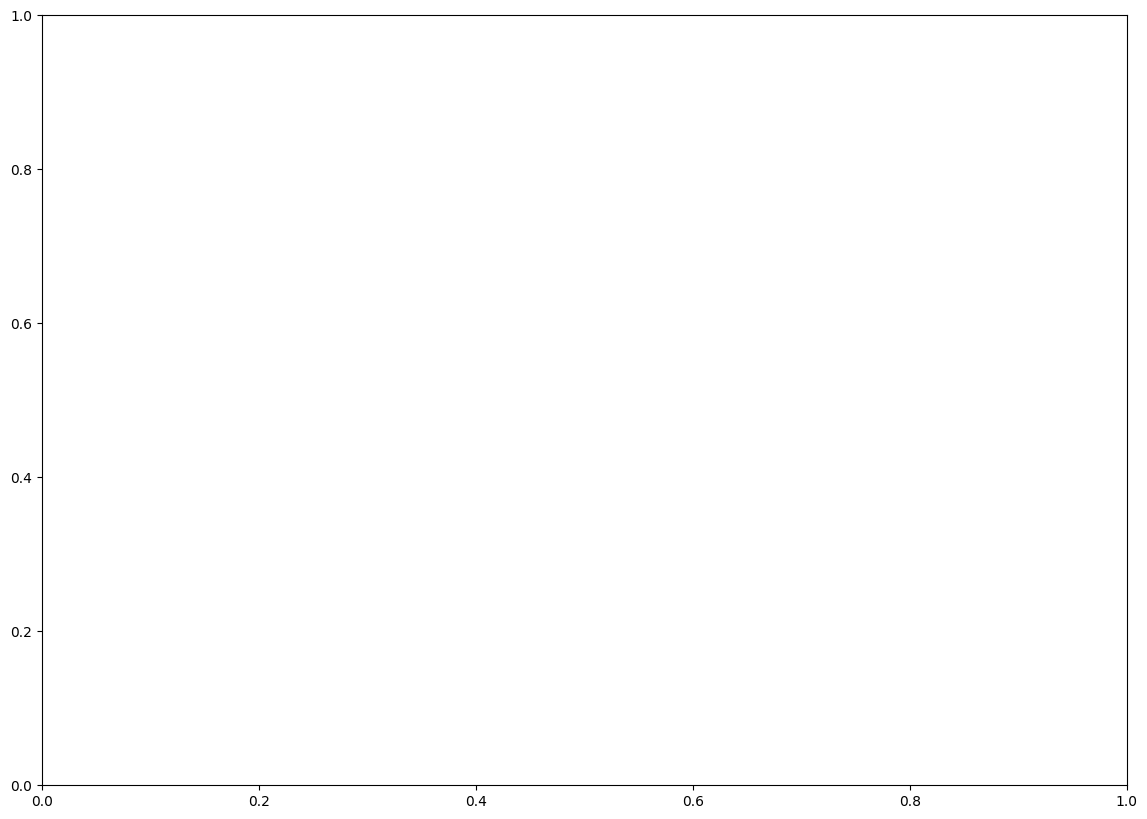

In [7]:
from draw.draw_sequences import draw_events_sequence
for i in range(len(seqs_goals_from_corners)):
    start_team = seqs_goals_from_corners[i]['possession_team']
    draw_events_sequence (seqs_goals_from_corners[i], start_team, 12, 8, scale=2,  first_event_360=True)

In [ ]:
len(matches_2022_2023_ids)